## Overview

This Power BI report translates the analytical results of the CLV modeling pipeline into decision-maker-ready dashboards designed for marketing, CRM, and commercial decision-making. The dashboards are built on a clean star-schema data model and focus on customer value, segmentation, retention risk, and targeting uplift, rather than raw transactional reporting.

The report answers not just what happened with the business, but **which customers matter, which to target, and where future revenue is likely to come from**.

The interactive `retail_clv.pbix` file is available upon request and is not included in the repo. All metric definitions are available in `power-bi/dax_measures.txt`. Model assumptions and relationships are documentd in `power-bi/model_notes.md`.

### Data Source

- **Online Retail II Dataset** - UCI Machine Learning Repository (via Kaggle).
- Transactions for a UK-based online retail company from 01/12/2009 to 09/12/2011.

### Data Model

The Power BI model follows a star schema:

#### Fact Table

- **`fact_transactions`** - Cleaned transaction-level data. One row per invoice line. Used for revenue, order, and trend analysis. Contains 804,008 rows.

#### Dimension Tables

- **`dimension_customers`** - Unified customer dimension. Includes RFM metrics, segment labels, behavioral features, and both CLV estimates. Contains 5,840 rows.
- **`dimension_date`** - Calendar table for time intelligence and trend analysis.

#### Relationships

- `fact_transactions.CustomerID` → `dimension_customers.CustomerID` (many-to-one).
- `fact_transactions.DateKey` → `dimension_date.DateKey` (many-to-one).

All customer-level analytics (segmentation, CLV slicing, targeting) are driven through the single `dimension_customers` table.

#### Coverage Notes

The following null values are structural and should not be treated as data quality issues:

|Field |Null Count |Reason |
|------|-----------|-------|
|`CLV_12m` |1,669 |One-time buyers cannot be modeled by Gamma-Gamma. |
|`CLV_6m_pred` |908 |Customers acquired after the ML cutoff date (June 9, 2011). |

### CLV Methodologies Used

The report surfaces two complementary CLV approaches:

|Methodology |Horizon |Use Case |
|------------|--------|---------|
|BG/NBD + Gamma-Gamma (Probabilistic) |12-Month |Stable, interpretable long-term value estimates for strategic planning. |
|Random Forest (ML-Predicted) |6-Month |Short-term ranking and prioritization for tactical targeting. |

### Model Performance Summary

**Probabilistic CLV (12-Month):**
- Mean: £1,808
- Median: £725
- Coverage: 4,171 of 5,840 customers (repeat buyers only).

**ML CLV (6-Month):**
- MAE: £651
- Median AE: £220
- R²: 0.592
- 45.5% improvement over mean-prediction baseline.
- Coverage: 4,932 of 5,840 customers (pre-cutoff customers only).

### Dashboard Pages

#### Executive Overview

**Purpose:** High-level business snapshot of revenue, customers, and value.

**Core Visuals:**
- KPI cards: Total Revenue, Orders, Customers, Avg CLV (12M), Avg CLV (6M).
- Revenue trend over time (monthly granularity).
- Revenue by customer segment.
- Top 20 customers by predicted CLV.

**Key Insight:**

Monthly revenue follows a strong cyclical pattern with Q4 peaks (November/December) and January slumps. CLV estimates and segment comparisons must account for seasonality, ignoring it risks misclassifying customers acquired or active during seasonal peaks as high-value when their behavior reflects timing and not loyalty.

**Audience:** Executives, senior stakeholders.

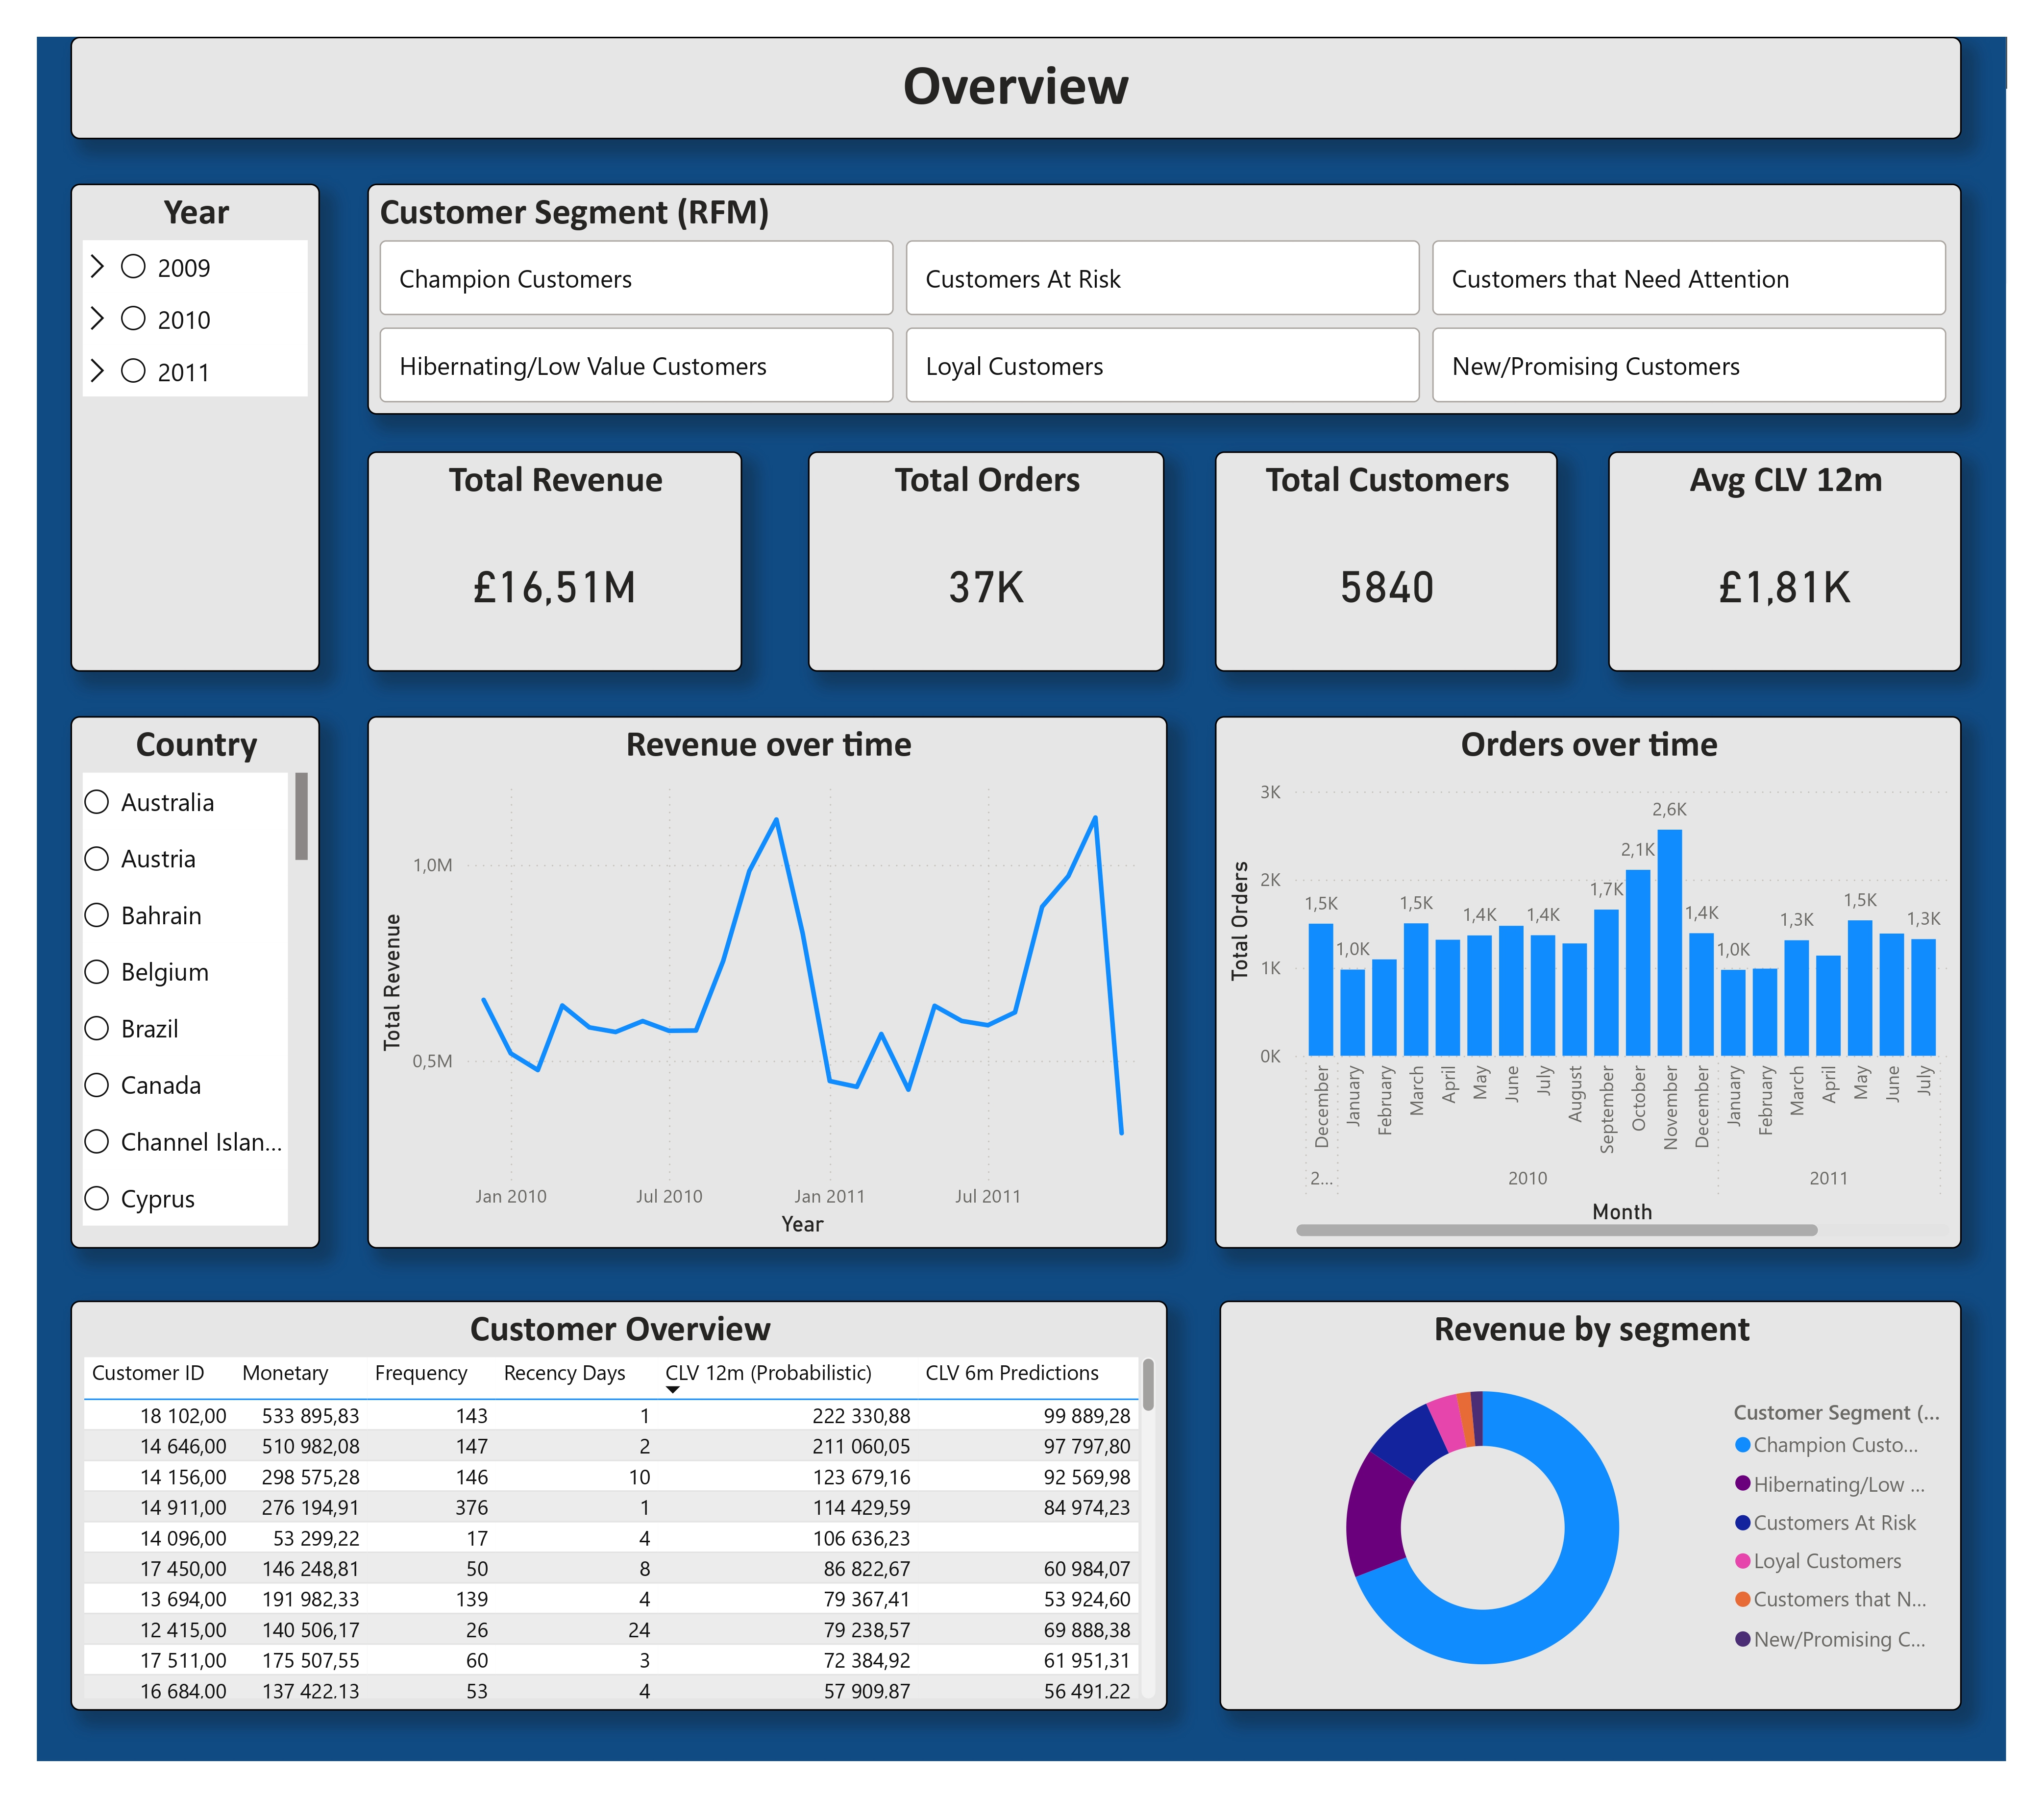

---

#### Customer Segmentation

**Purpose:** Understand customer archetypes and their differing value profiles.

**Core Visuals:**
- Customer count by RFM segment.
- Average CLV by segment (12-month and 6-month).
- Recency vs. Frequency scatter (bubble size = monetary spend).
- Segment profile matrix (customers, revenue, CLV).

**Key Insight:**

Customer behavior is deeply heterogeneous. RFM and K-Means reveal distinct archetypes - Champions (£4,280 avg CLV), Loyal (£884), At Risk (£381), and Hibernating (£880) - each requiring differentiated strategies. The Need Attention segment (241 customers) shows higher short-term CLV (£532) than both At Risk (£420) and Loyal (£369), indicating latent re-engagement potential that RFM scores alone would miss.

**Audience:** Marketing, CRM, analytics teams.

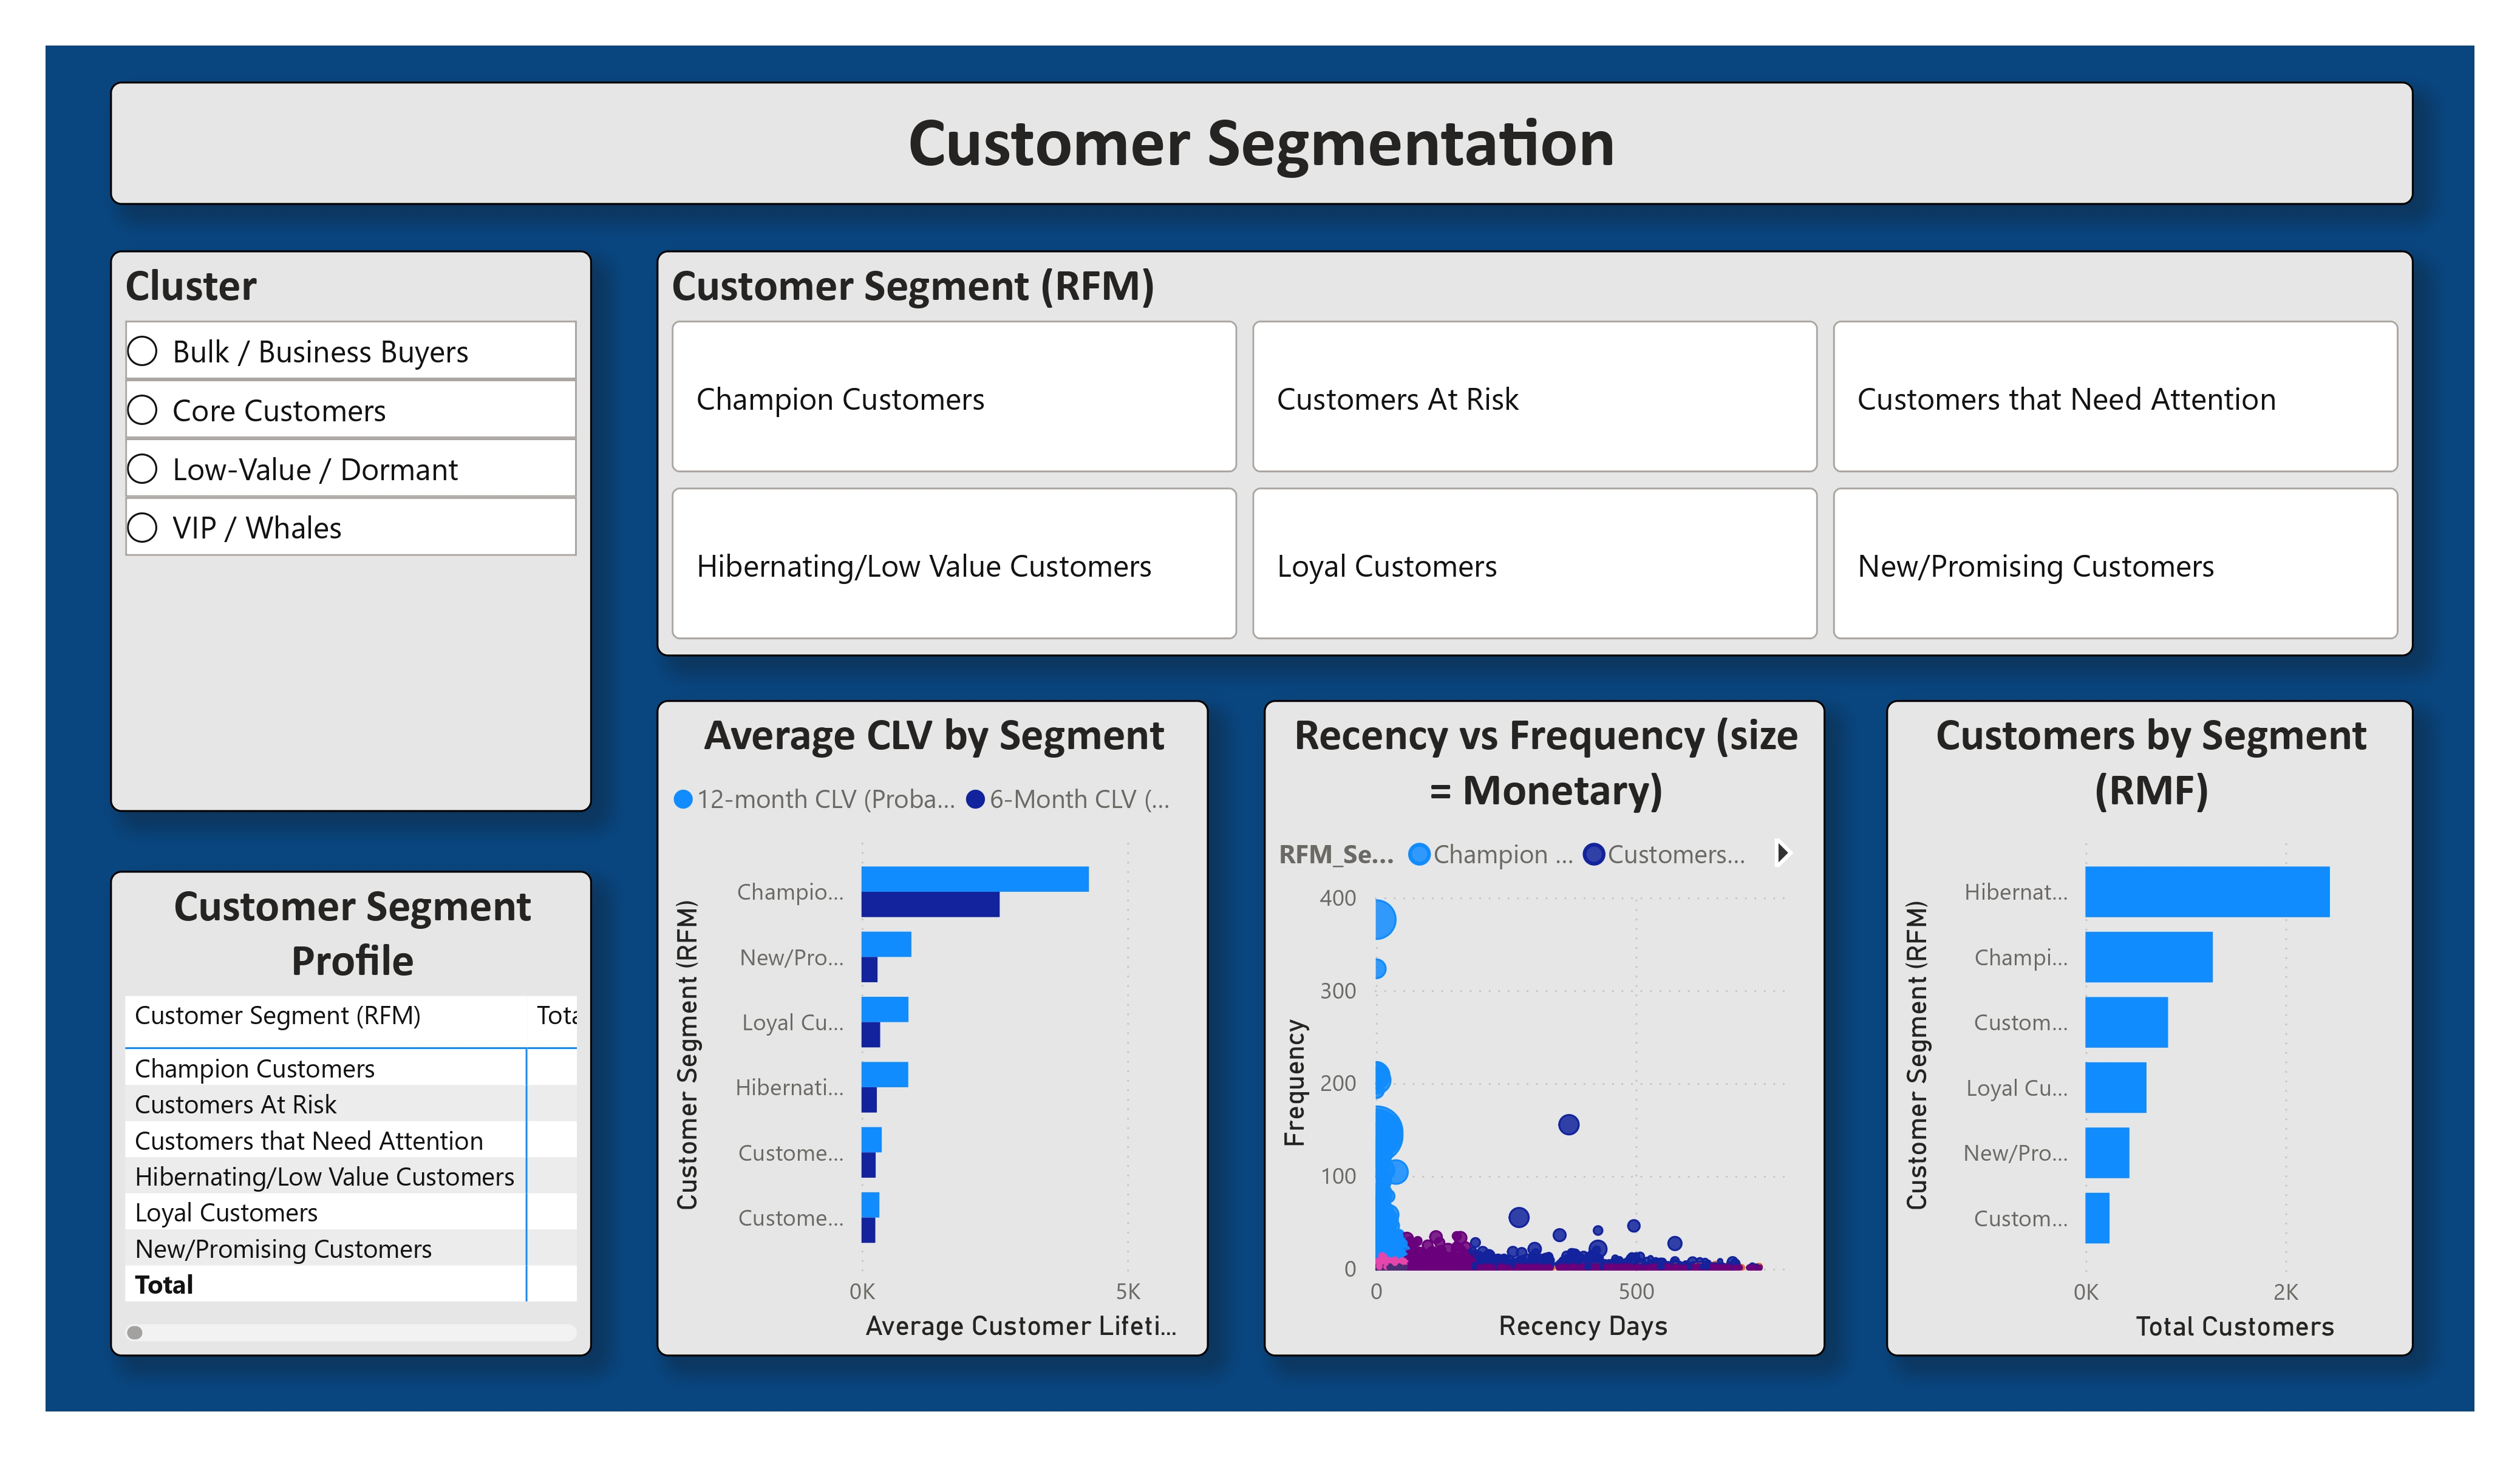

---

### CLV Modeling and Distribution

**Purpose:** Provide transparency into CLV outputs and value concentration.

**Core Visuals:**
- Distribution of 12-month probabilistic CLV.
- Distribution of 6-month ML-predicted CLV.
- Cumulative value (Pareto) curves.
- Segment-level CLV comparisons (mean and median).

**Key Insight:**

Revenue is highly concentrated. 24.2% of customers drive 80% of total revenue. The top 5% of ML-ranked customers capture 52% of near-term revenue. Customer value distributions show a long right tail - mean CLV (£1,808) is 2.5X the median (£725), confirming that a small minority disproportionately sustains the business.

**Audience:** Analytics, data science stakeholders.

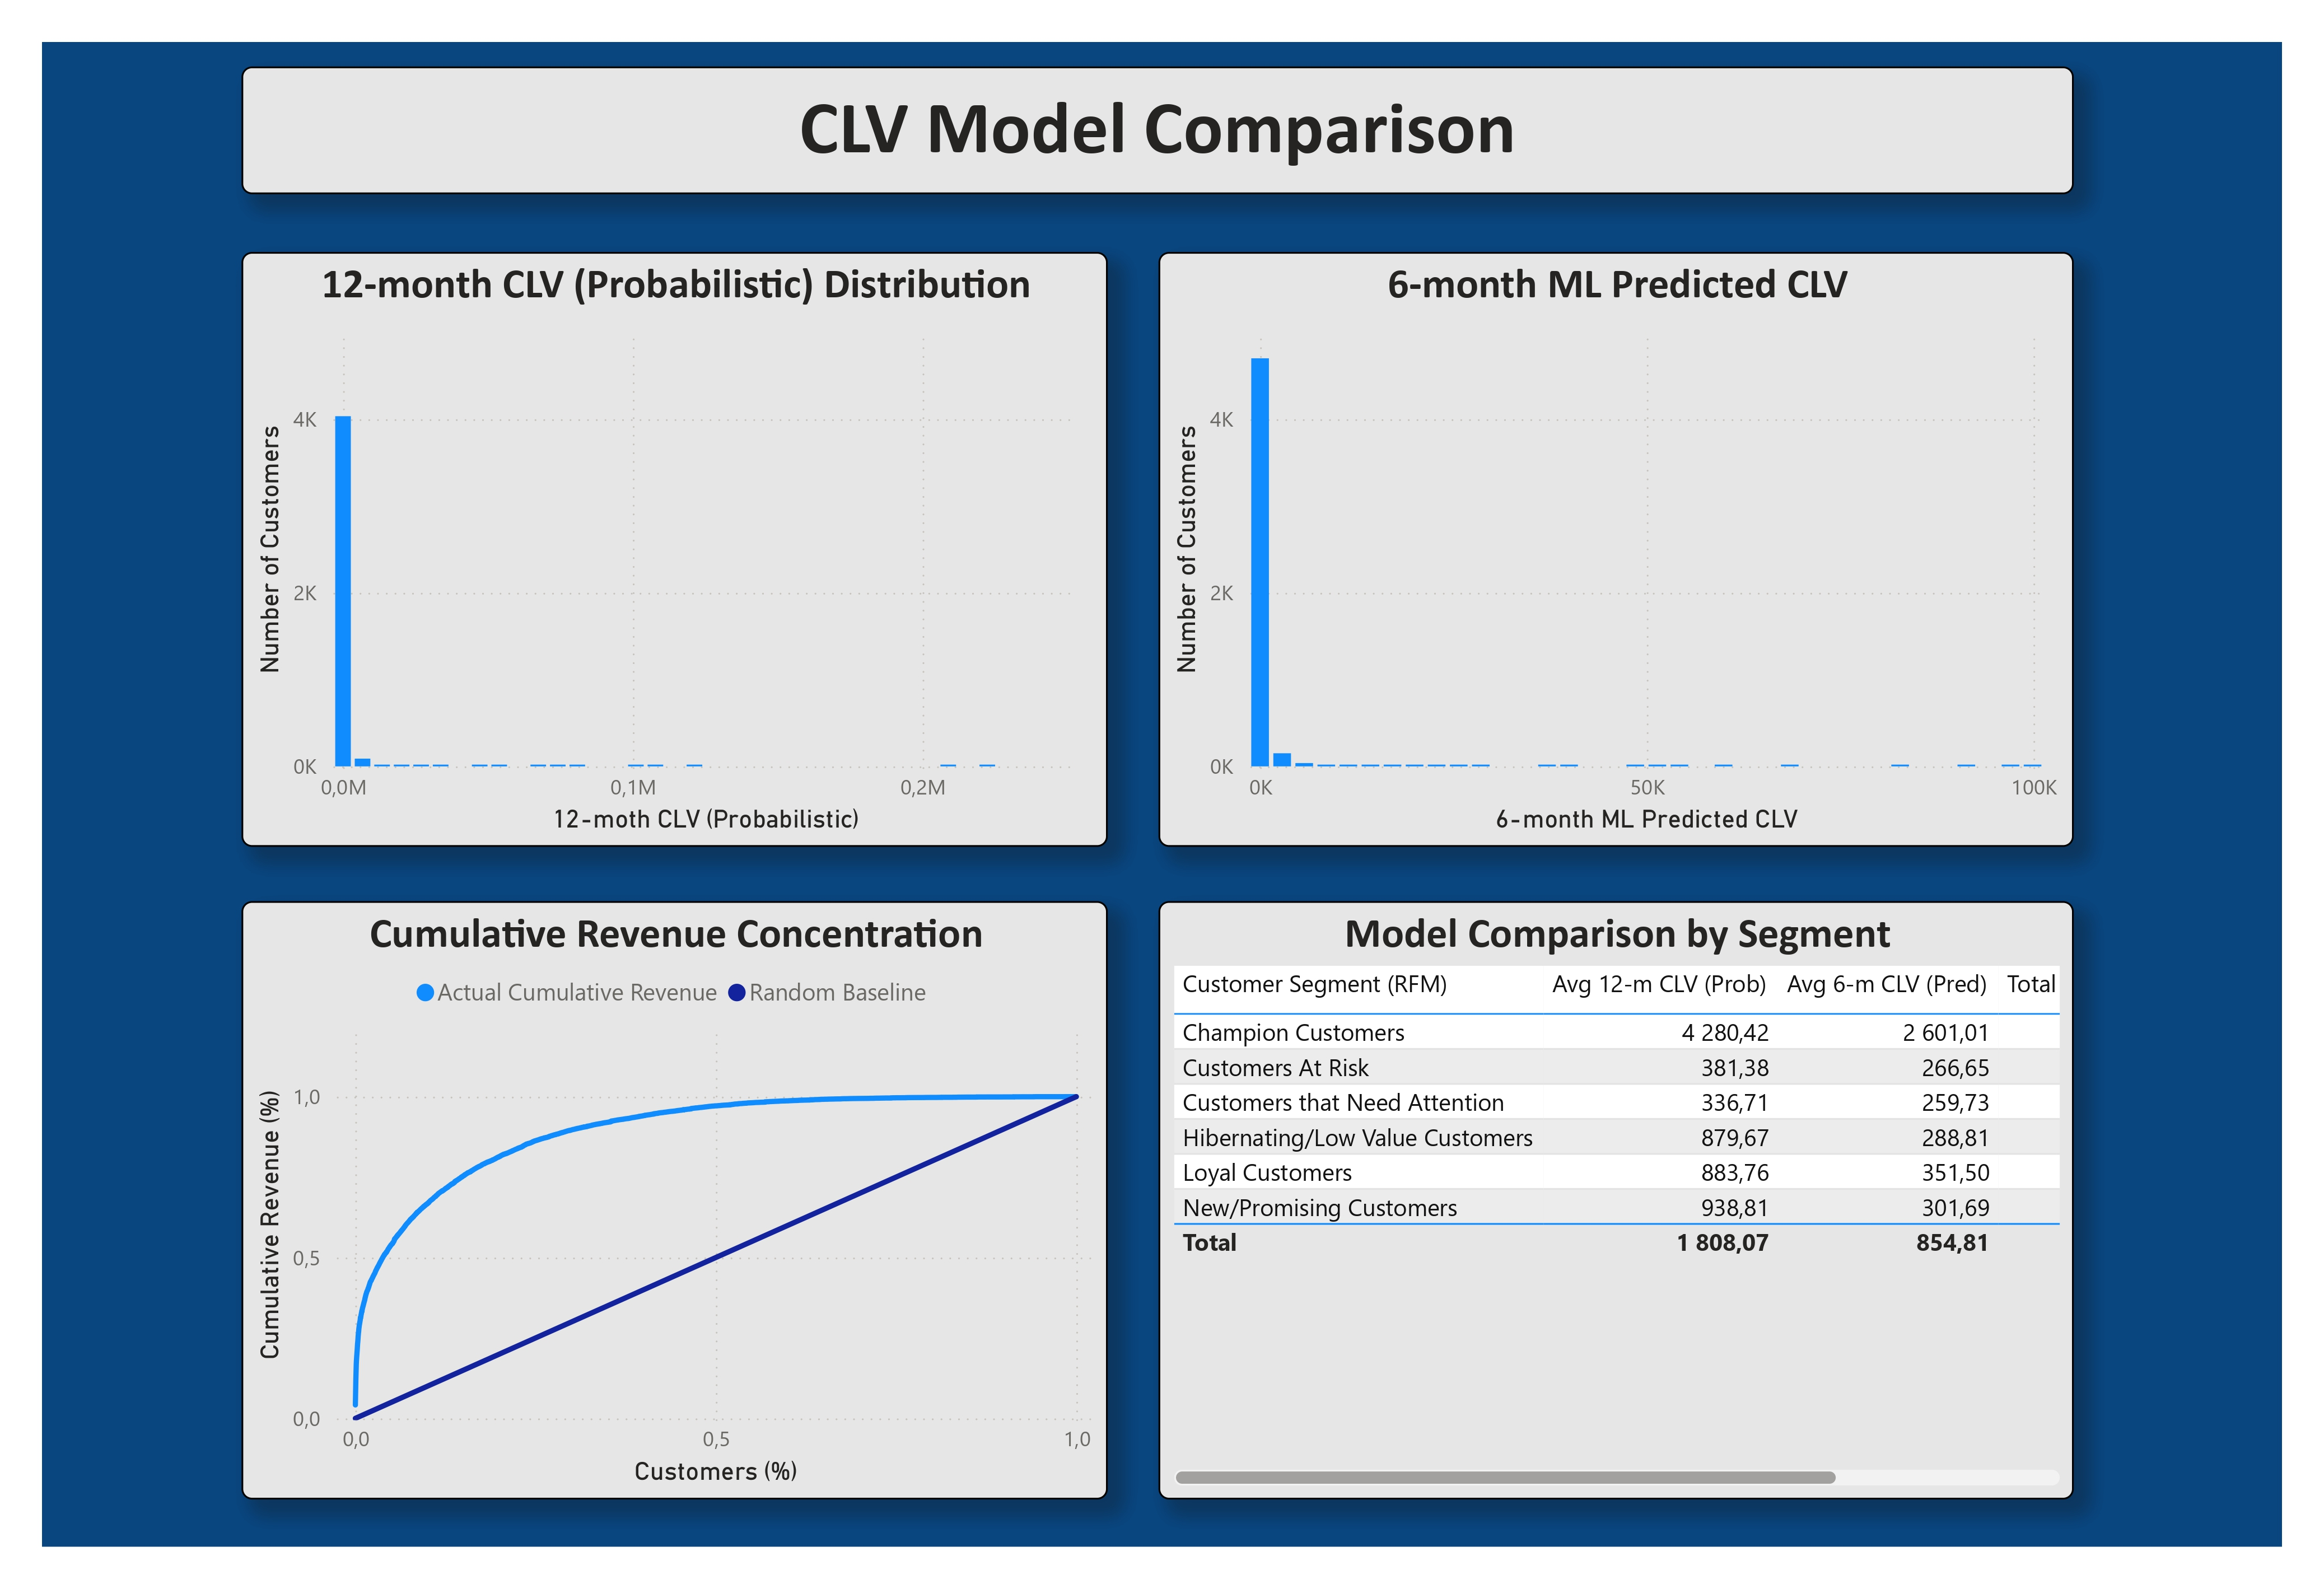

---

### Targeting and Revenue Uplift

**Purpose:** Translate CLV into concrete marketing actions and budget allocation guidance.

**Core Visuals:**
- Top X% selector (parameter-driven, 1-20%).
- Revenue captured by targeting top CLV customers.
- Comparison against random targeting baseline.
- Lift multiplier at each threshold.
- Table of targetable customers with segment labels.

**Key Insight:**

CLV-driven targeting delivers measurable uplift:

|Threshold |Revenue Captured |Lift vs Random |
|----------|-----------------|---------------|
|Top 1% |33% |32.7X |
|Top 5% |52% |10.5X |
|Top 10% |65% |6.5X |
|Top 20% |79% |4.0X |

**Caveat:** These results are in-sample. The model was trained on the same period being evaluated. Uplift is treated as model capability and not guaranteed field performance. A rolling-origin validation would be needed for out-of-sample estimates.

**Audience:** Marketing strategy, growth teams.

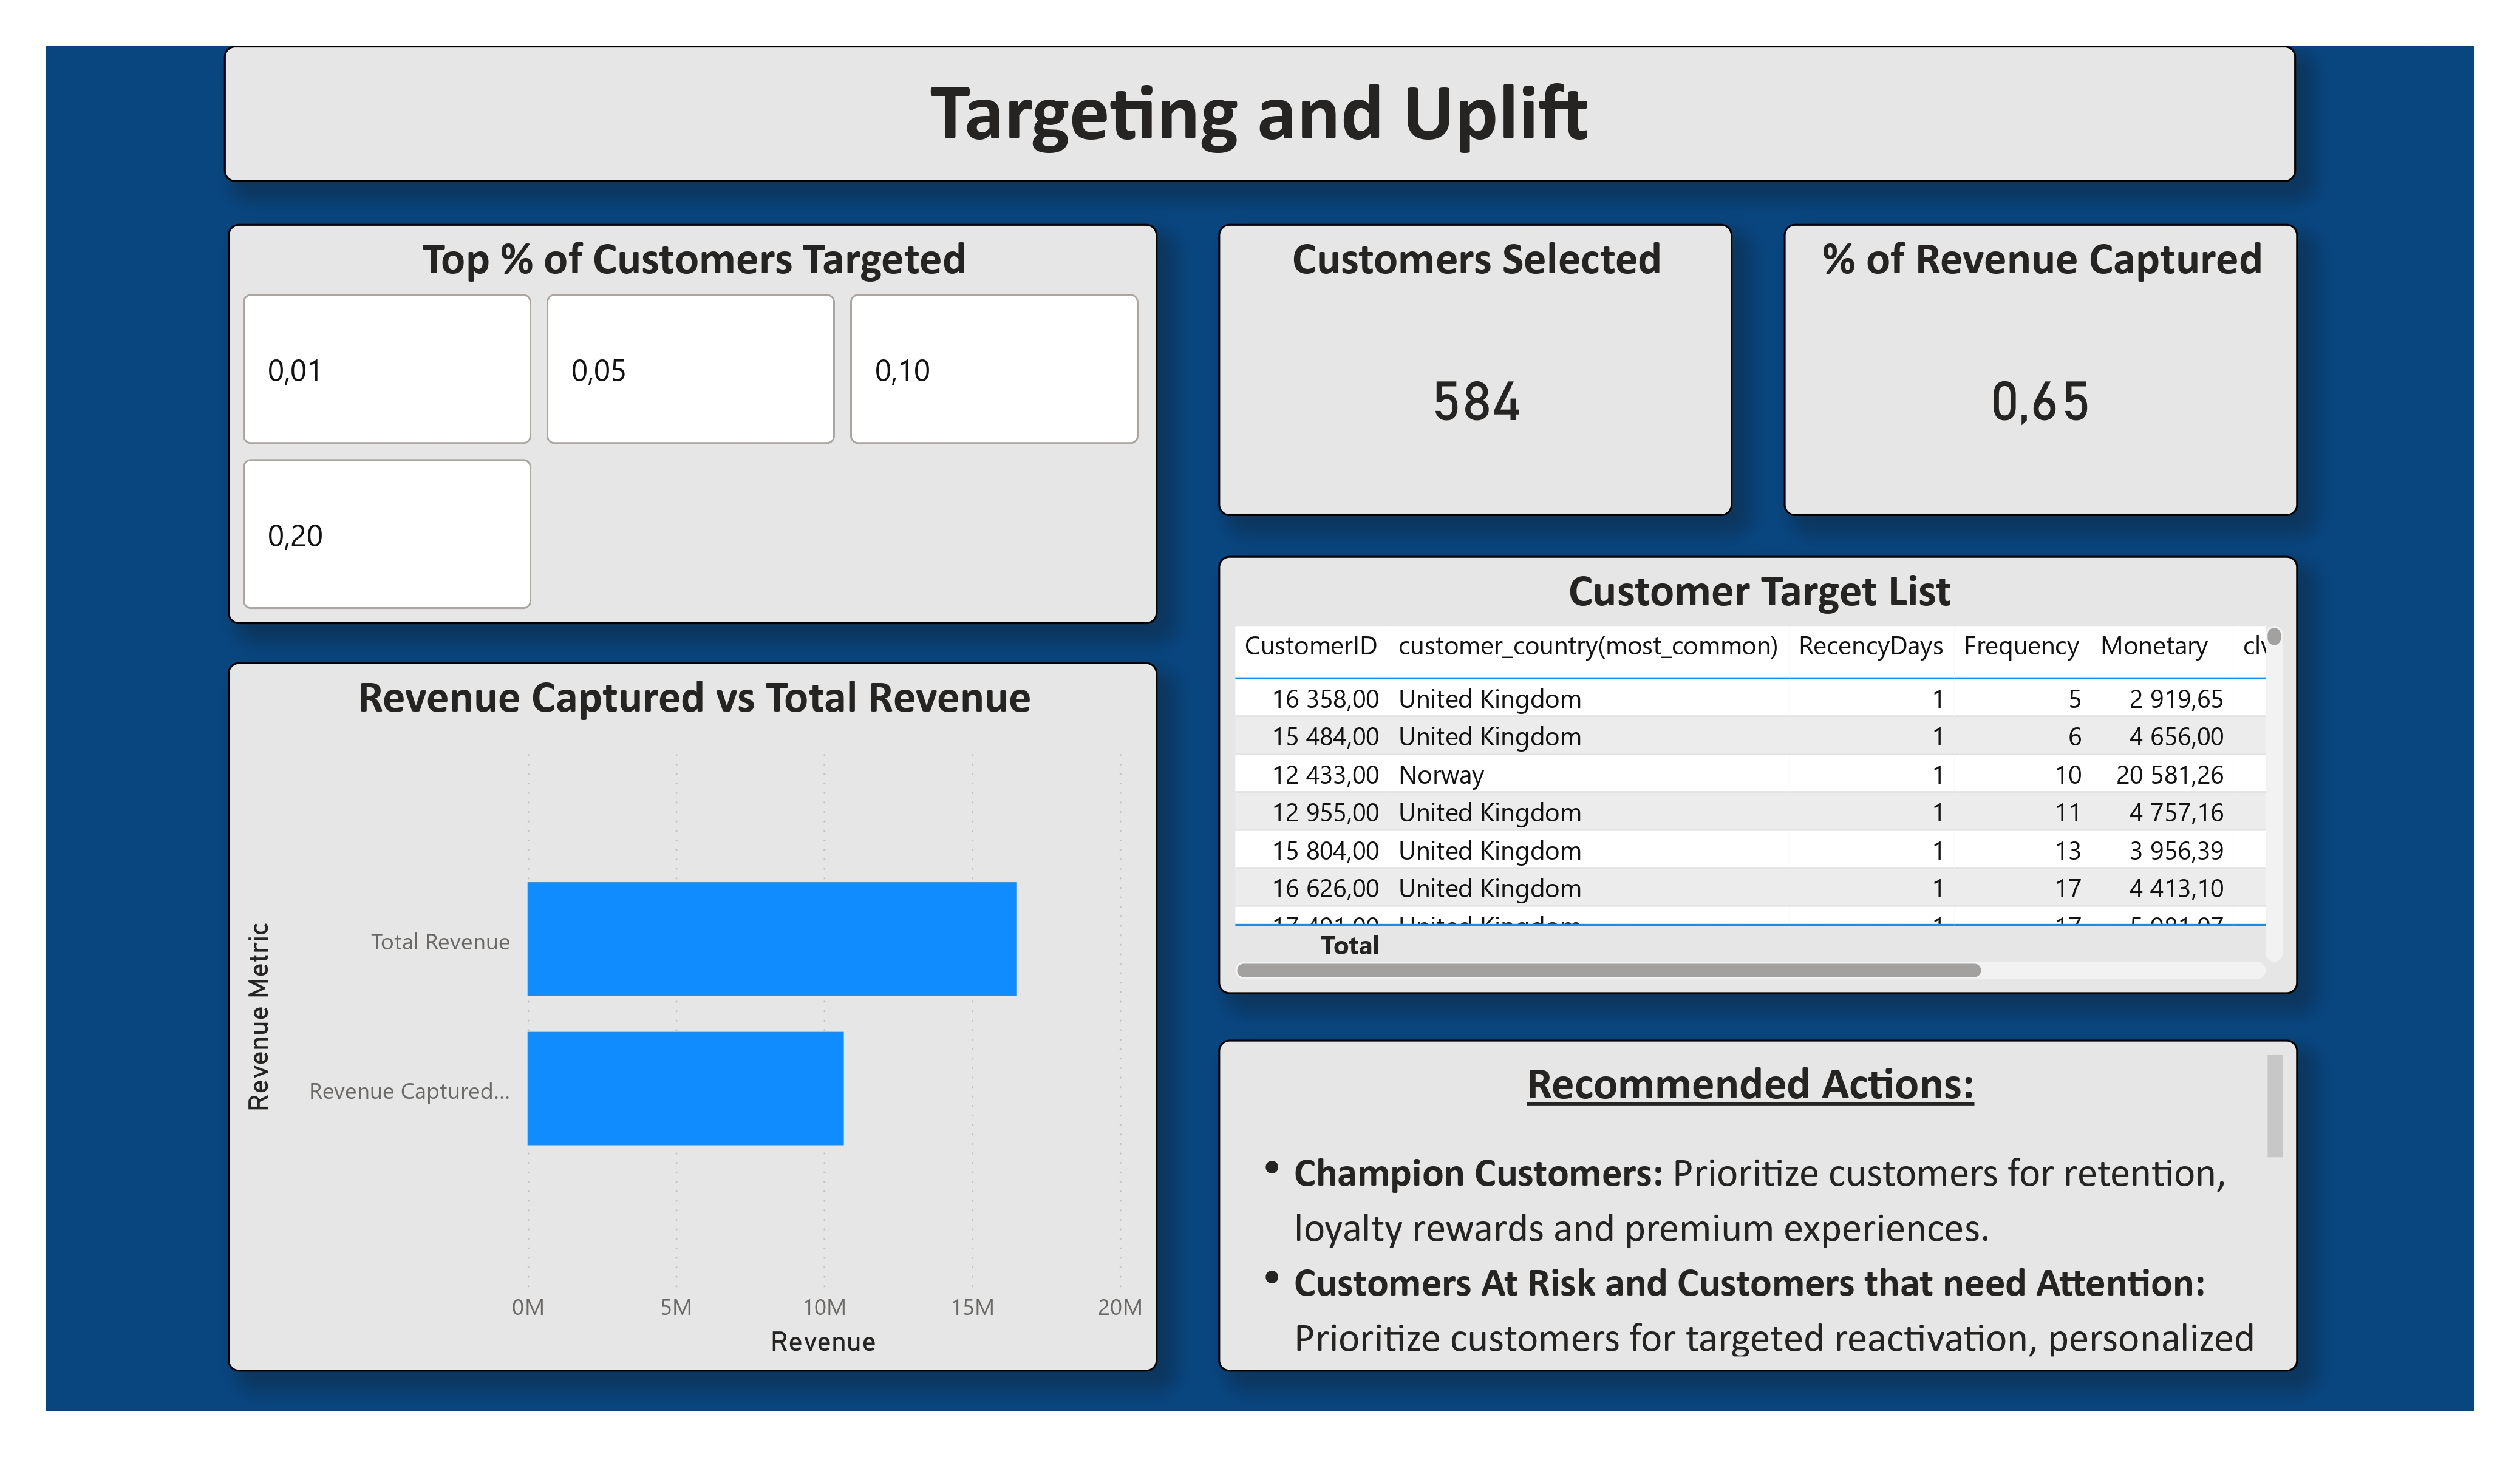

---

### Retention and Recency Analysis

**Purpose:** Identify churn risk and prioritize retention interventions.

**Core Visuals:**
- Customers by recency band.
- Average CLV by recency band.
- Recency vs. CLV scatter.
- Segment overlay for At Risk and Need Attention.

**Key Insight:**

The Need Attention segment warrants elevated priority despite RFM classification as low-value. These customers show short-term CLV (£532) exceeding At Risk (£420) and Loyal (£369), indicating the ML model has identified latent re-engagement signals. High-CLV, lapsed customers represent recoverable revenue - the business already invested in acquiring them, and reactivation is typically cheaper than new acquisition.

**Audience:** CRM, lifecycle marketing teams.

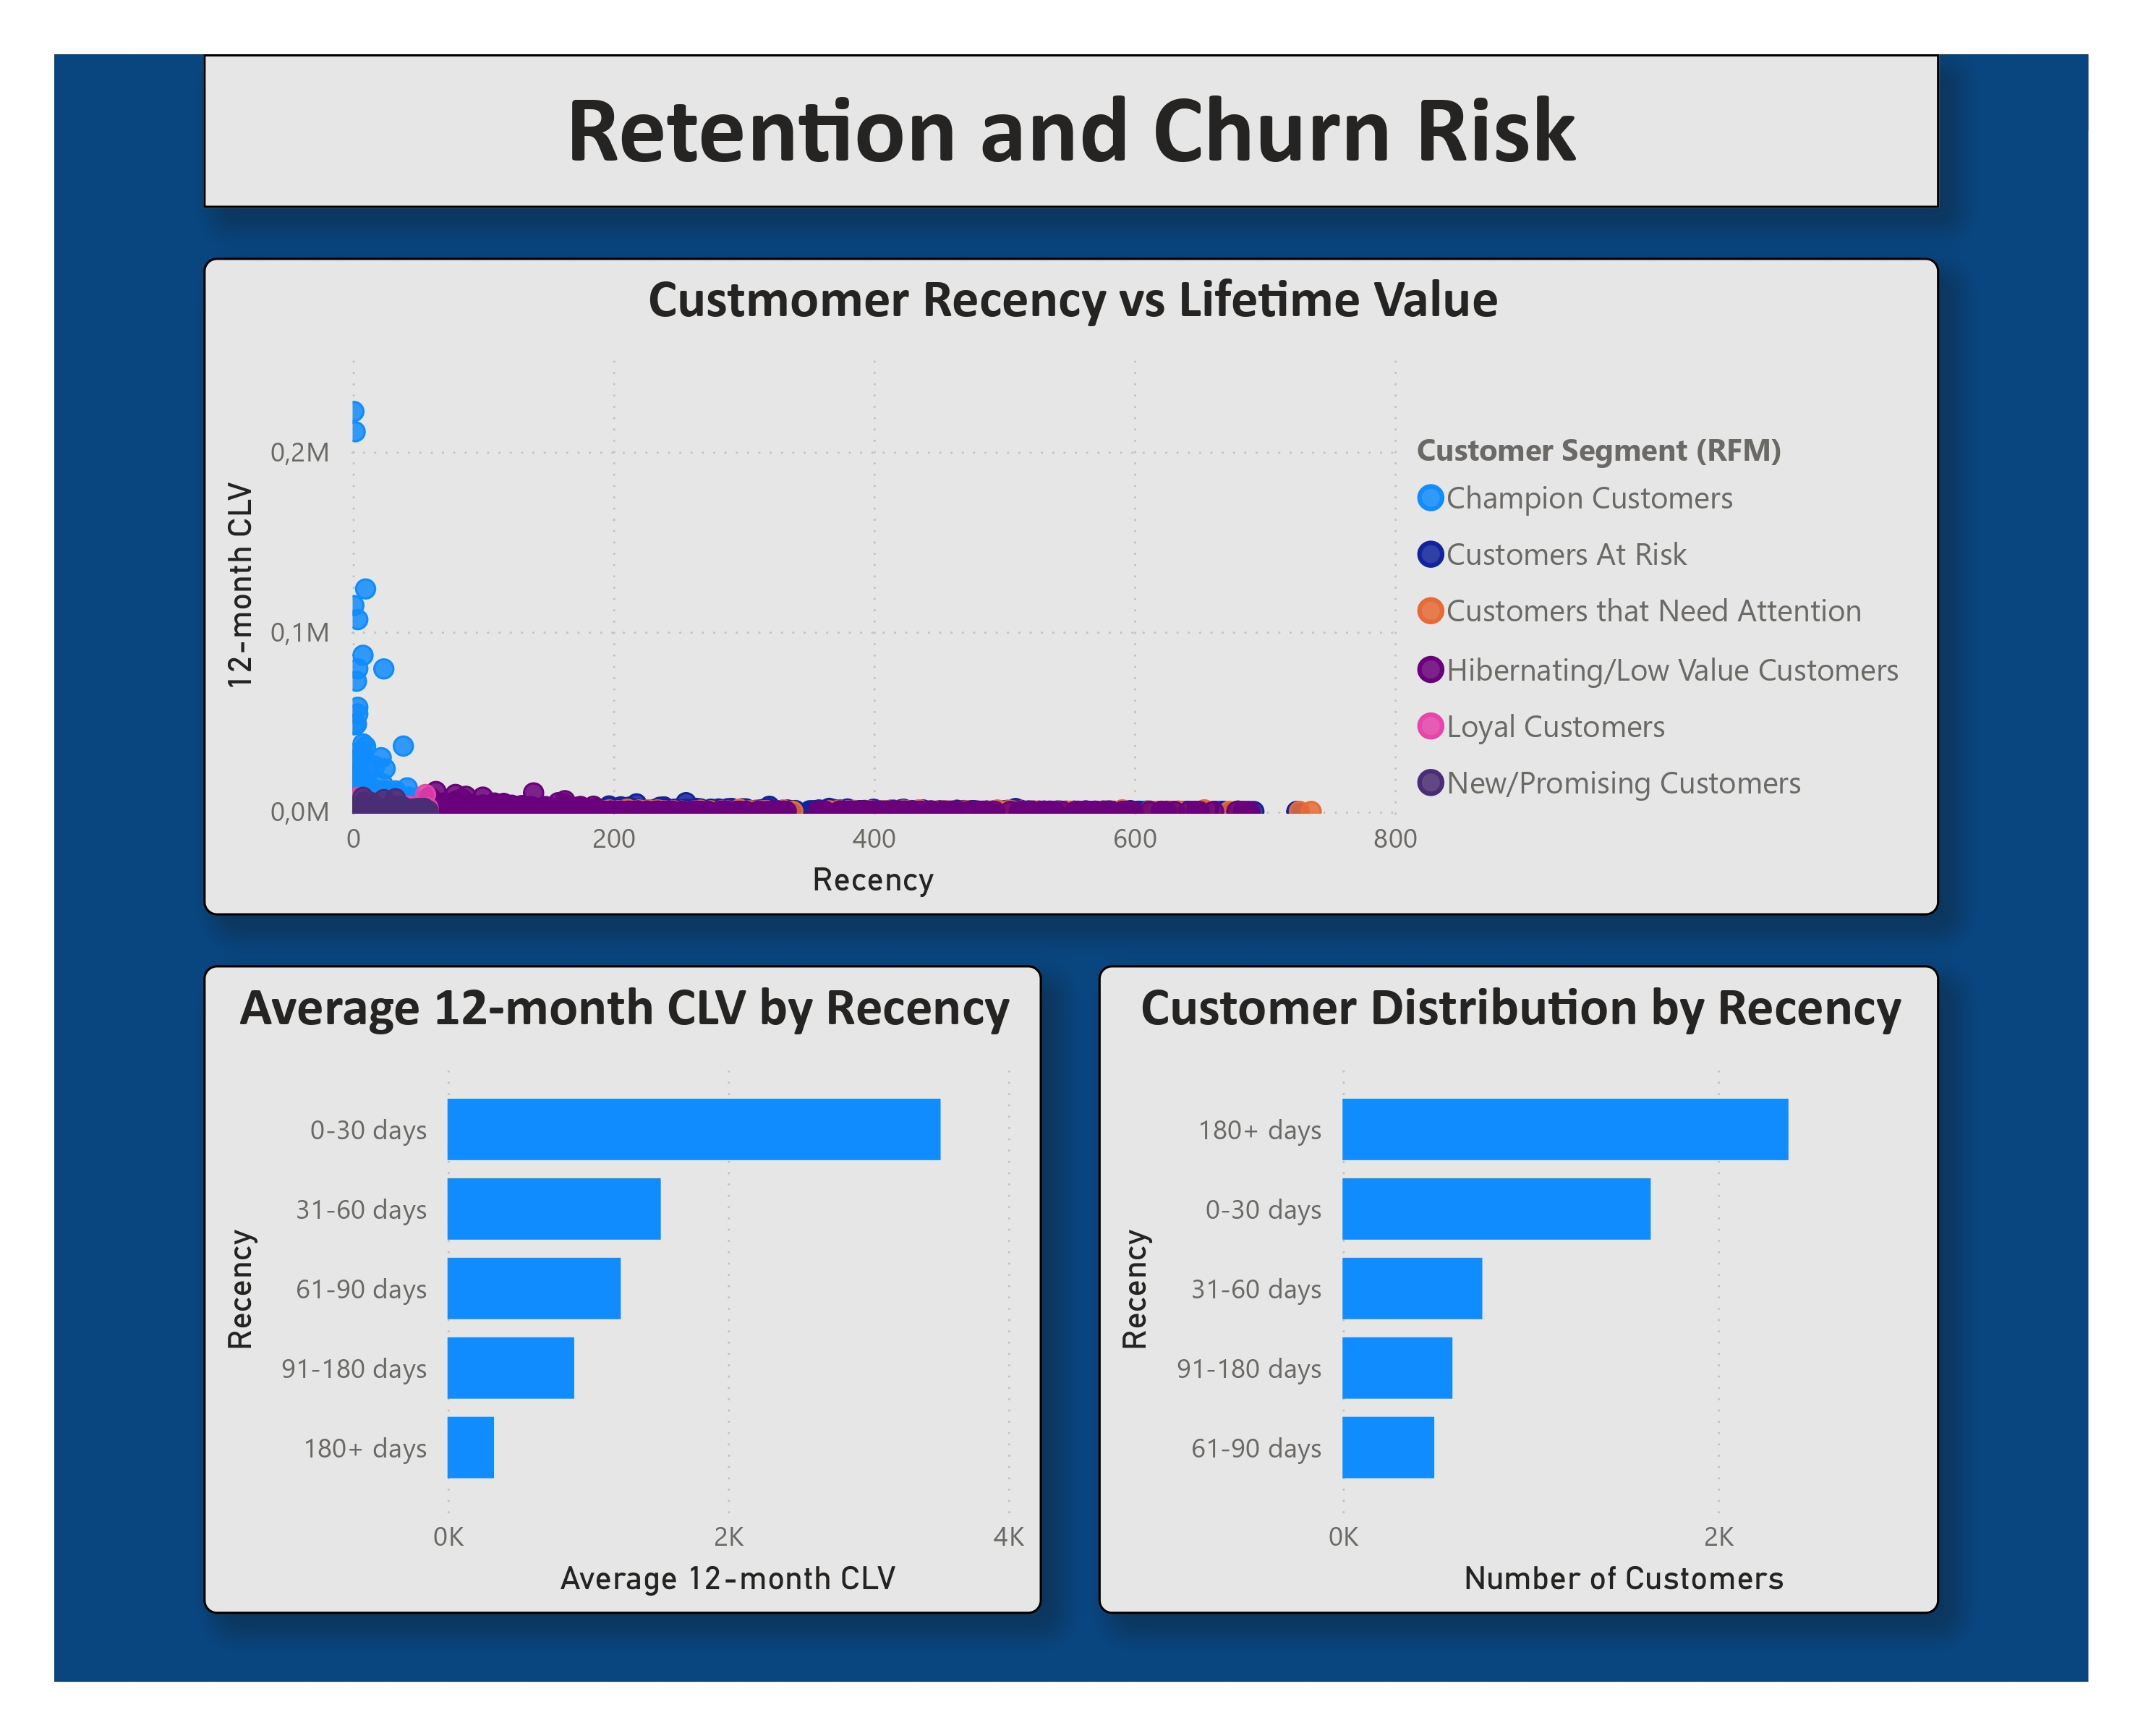

---

### Customer Drill-Through

**Purpose:** Enable customer-level investigation from any dashboard page.

**Core Visuals:**
- Customer KPIs (Recency, Frequency, Monetary, both CLV estimates).
- Customer revenue trend over time.
- Recent transaction history.
- Segment and cluster assignment.

This page supports ad-hoc investigation and CRM list-building.

---

## Measures and Calculations

The report uses curated DAX measures:

- Revenue, Orders, Average Order Value (AOV).
- Average and total CLV (12-month and 6-month).
- Median CLV (robust to outliers).
- Customer ranking by predicted CLV.
- Revenue capture and uplift metrics.
- Recency-based activity indicators.

Measures respond consistently to date, segment, and customer slicers.

**Note on median:** Where possible, median CLV should be used alongside mean. The heavy right-skew means mean values are pulled upward by high-value outliers. Median provides a more representative view of the typical customer.

## Usage Notes

- Date slicers should only use the `dimension_date` table.
- Customer-level visuals should be driven from `dimension_customers`.
- CLV values are predictions and should be interpreted directionally, and not as exact forecasts.
- Null CLV values are structural (see Coverage Notes).
- The report is optimized for strategic insights.

## Technical Setup

### Prerequisites

- Power BI Desktop. 
- Access to exported data from the CLV pipeline.

## File Structure
```
data/
    fact_transactions.csv
    dim_customer.csv
power_bi/
    dax_measures.txt
    model_notes.md
```

## Intended Outcomes

This Power BI report enables stakeholders to:

1. **Shift focus from historical revenue to future value** - CLV estimates replace backward-looking revenue as the primary lens.
2. **Prioritize customers and segments by predicted impact** - both 6-month and 12-month horizons.
3. **Design targeted, data-driven marketing actions** - with specific segments mapped to specific strategies.
4. **Understand revenue concentration and risk** - Pareto curves, recency bands, and segment profiles.
5. **Quantify the value of CLV-driven targeting** - uplift curves provide the business case for model-guided allocation.